# ch02_5. 다중 선형회귀

## 세 개의 시험 점수로 최종 점수 예측하기

## 개요

- Multiple Linear Regression(멀티플 리니어 리그레션, 다중 선형회귀)의 구조를 이해합니다.
- 새로운 학생의 최종 점수를 예측합니다.

## 1. 시험 점수 데이터 준비

입력 특성은 세 개입니다.

- $x_1$: Quiz 1(퀴즈 원, 첫 번째 퀴즈)
- $x_2$: Quiz 2(퀴즈 투, 두 번째 퀴즈)
- $x_3$: Midterm(미드텀, 중간시험)
- $y$: Final Score(파이널 스코어, 최종 점수)

각 행은 학생 한 명의 데이터입니다.

| 학생 | Quiz 1 | Quiz 2 | Midterm | Final |
|---:|---:|---:|---:|---:|
| 1 | 73 | 80 | 75 | 152 |
| 2 | 93 | 88 | 93 | 185 |
| 3 | 89 | 91 | 90 | 180 |
| 4 | 96 | 98 | 100 | 196 |
| 5 | 73 | 66 | 70 | 142 |

In [ ]:
#01.데이터 준비
import torch
from torch import nn
import matplotlib.pyplot as plt

x_train = torch.tensor(
    [
        [73.0, 80.0,  75.0],
        [93.0, 88.0,  93.0],
        [89.0, 91.0,  90.0],
        [96.0, 98.0, 100.0],
        [73.0, 66.0,  70.0],
    ],
    dtype=torch.float32,)

y_train = torch.tensor(
    [[152.0], [185.0], [180.0], [196.0], [142.0]], 
    dtype=torch.float32,)

print("입력 shape:", x_train.shape)
print("목표값 shape:", y_train.shape)

입력 shape: torch.Size([5, 3])
목표값 shape: torch.Size([5, 1])


## 2. 다중 선형회귀식

입력 특성이 세 개이면 가중치도 세 개입니다.

$$
\hat{y}
=
w_1x_1+w_2x_2+w_3x_3+b
$$

계산 순서:

1. 각 입력과 가중치를 곱합니다.
2. 곱한 값을 모두 더합니다.
3. 편향 $b$를 더합니다.

입력이 여러 개로 늘어났을 뿐, 단일 선형회귀와 계산 원리는 같습니다.

In [ ]:
#02. 첫 번째 학생을 예로 직접 계산합니다.
first_student = x_train[0]

sample_weight = torch.tensor([0.5, 0.8, 0.7])   # 가중치 가설
sample_bias = 10.0

sample_prediction = (first_student * sample_weight).sum() + sample_bias

print("첫 번째 학생 점수:", first_student)
print("예시 예측값:", sample_prediction.item())

첫 번째 학생 점수: tensor([73., 80., 75.])
예시 예측값: 163.0


## 3. 특성별 표준화

세 시험의 점수 분포가 다를 수 있으므로 각 열을 따로 표준화합니다.

$$
x_{\mathrm{scaled}}
=
\frac{x-\mu}{\sigma}
$$

- Quiz 1은 Quiz 1의 평균과 표준편차 사용
- Quiz 2는 Quiz 2의 평균과 표준편차 사용
- Midterm은 Midterm의 평균과 표준편차 사용

목표값 $y$는 실제 점수 단위를 유지합니다.

In [ ]:
#03. 각 열의 평균과 표준편차
x_mean = x_train.mean(dim=0)
x_std = x_train.std(dim=0)

# 각 열을 따로 표준화
x_train_scaled = (x_train - x_mean) / x_std

print("특성별 평균:", x_train_scaled.mean(dim=0))
print("특성별 표준편차:", x_train_scaled.std(dim=0))

특성별 평균: tensor([-2.3842e-07,  1.1921e-07,  1.4305e-07])
특성별 표준편차: tensor([1., 1., 1.])


In [ ]:
#<참고> 부분 값 확인
print("x_train : \n",x_train)
print("x_mean : \n", x_mean)
print("x_train - x_mean : \n", x_train - x_mean)
print("x_std : \n", x_std)

print("x_train_scaled : \n", x_train_scaled)

print("특성별 평균: \n", x_train_scaled.mean(dim=0))
print("특성별 표준편차: \n", x_train_scaled.std(dim=0))

x_train : 
 tensor([[ 73.,  80.,  75.],
        [ 93.,  88.,  93.],
        [ 89.,  91.,  90.],
        [ 96.,  98., 100.],
        [ 73.,  66.,  70.]])
x_mean : 
 tensor([84.8000, 84.6000, 85.6000])
x_train - x_mean : 
 tensor([[-11.8000,  -4.6000, -10.6000],
        [  8.2000,   3.4000,   7.4000],
        [  4.2000,   6.4000,   4.4000],
        [ 11.2000,  13.4000,  14.4000],
        [-11.8000, -18.6000, -15.6000]])
x_std : 
 tensor([11.0544, 12.2393, 12.6214])
x_train_scaled : 
 tensor([[-1.0674, -0.3758, -0.8398],
        [ 0.7418,  0.2778,  0.5863],
        [ 0.3799,  0.5229,  0.3486],
        [ 1.0132,  1.0948,  1.1409],
        [-1.0674, -1.5197, -1.2360]])
특성별 평균: 
 tensor([-2.3842e-07,  1.1921e-07,  1.4305e-07])
특성별 표준편차: 
 tensor([1., 1., 1.])


## 4. 다중 선형회귀 모델

입력 특성이 세 개이고 출력이 하나이므로 다음 계층을 사용합니다.

```python
nn.Linear(3, 1)
```

| 항목 | shape |
|---|---|
| 입력 | `[5, 3]` |
| 가중치 | `[1, 3]` |
| 편향 | `[1]` |
| 출력 | `[5, 1]` |

별도의 모델 클래스를 만들지 않고 선형 계층 하나를 바로 사용합니다.

In [ ]:
#04. 다중 선형회귀 모델

torch.manual_seed(42)

model = nn.Linear(3, 1)

print(model)
print("가중치 shape:", model.weight.shape)
print("편향 shape:", model.bias.shape)

Linear(in_features=3, out_features=1, bias=True)
가중치 shape: torch.Size([1, 3])
편향 shape: torch.Size([1])


## 5. 모델 학습

학습 순서는 와 같습니다.

$$
\text{순전파}
\rightarrow
\text{손실}
\rightarrow
\text{역전파}
\rightarrow
\text{갱신}
$$

입력 특성이 세 개이므로 세 개의 가중치가 함께 학습됩니다.

In [ ]:
#05. 모델 학습
loss_function = nn.MSELoss()

optimizer = torch.optim.SGD(model.parameters(),lr=0.05,)
epochs = 1500
loss_history = []

for epoch in range(epochs):
    # 1. 순전파
    prediction = model(x_train_scaled)

    # 2. 손실 계산
    loss = loss_function(prediction, y_train,)
   
    # 3. 이전 기울기 초기화
    optimizer.zero_grad()

    # 4. 역전파
    loss.backward()

    # 5. 가중치와 편향 갱신
    optimizer.step()

    loss_history.append(loss.item())

print("처음 Loss:", loss_history[0])
print("마지막 Loss:", loss_history[-1])

처음 Loss: 29453.453125
마지막 Loss: 0.10819890350103378


## 6. 손실 변화 확인

학습이 진행되면서 MSE Loss(엠에스이 로스, 평균제곱오차 손실)가 감소하는지 확인합니다.

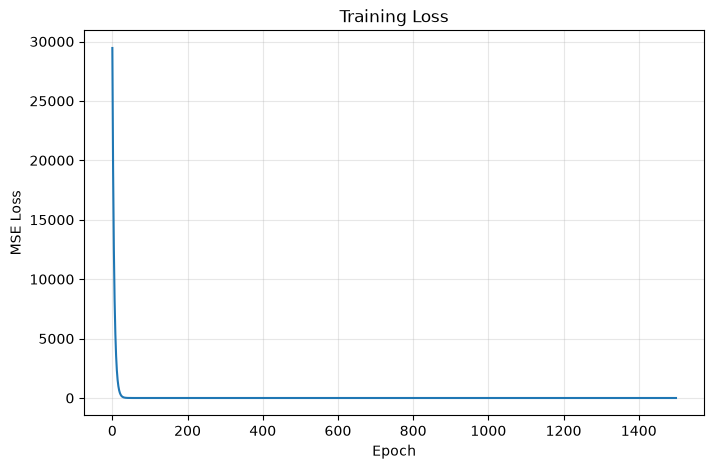

In [ ]:
#06. 손실변화 확인
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

## 7. 실제 점수와 예측 점수 비교

현재 데이터는 5개뿐이므로 훈련 데이터와 테스트 데이터로 나누지 않습니다.

따라서 아래 결과는 **새로운 학생에 대한 성능**이 아니라, 현재 5개 데이터를 얼마나 잘 맞추었는지를 보여줍니다.

- torch.no_grad()(No Gradient, 기울기 계산 비활성화)는 자동 미분을 끄는 기능이고,
- torch.inference_mode()(Inference Mode, 추론 전용 모드)는 자동 미분뿐 아니라, 추론에 필요 없는 추가 추적 기능까지 더 강하게 끄는 기능

| 구분              | `torch.no_grad()` | `torch.inference_mode()` |
| --------------- | ----------------- | ------------------------ |
| Gradient 계산     | 끔                 | 끔                        |
| 계산 그래프 생성       | 안 함               | 안 함                      |
| View 추적 등 내부 관리 | 일부 유지             | 더 많이 비활성화                |
| 속도/메모리          | 절약                | **조금 더 절약 가능**           |
| 이후 Autograd 재사용 | 비교적 자유로움          | **제약이 더 큼**              |
| 권장 용도           | 일반적인 평가/부분 계산     | **완전한 추론·평가**            |

zip(집, 여러 데이터를 같은 위치끼리 묶는 함수)은 여러 개의 반복 가능한 데이터를 같은 순서끼리 묶어줍니다.


In [ ]:
#07_실제점수와 예측점수 비교
model.eval() # 모델을 평가상태로 전환

with torch.no_grad():
    predicted_score = model(x_train_scaled)

for actual, predicted in zip(y_train, predicted_score,):
    print(f"실제: {actual.item():6.1f} | "
        f"예측: {predicted.item():6.1f}")

실제:  152.0 | 예측:  151.7
실제:  185.0 | 예측:  184.5
실제:  180.0 | 예측:  180.4
실제:  196.0 | 예측:  196.2
실제:  142.0 | 예측:  142.2


## 8. 실제 점수 단위의 예측식

모델은 표준화된 입력을 사용하므로, 학습된 가중치를 원래 점수 단위로 바꾸어 해석합니다.

$$
\hat{y}
=
w_1x_1+w_2x_2+w_3x_3+b
$$

각 가중치는 **다른 시험 점수가 같을 때**, 해당 시험 점수가 1점 증가하면 최종 예측값이 얼마나 변하는지를 나타냅니다. 데이터가 5개뿐이므로 가중치를 확정적인 영향도로 해석해서는 안 됩니다.

In [ ]:
#08_실제점수 단위의 예측 식

scaled_weight = model.weight.detach().squeeze(0)
scaled_bias = model.bias.detach().squeeze(0)

# 표준화 이전 단위의 가중치와 편향
real_weight = scaled_weight / x_std

real_bias = (scaled_bias - torch.sum(real_weight * x_mean))

print("예측식:")
print(
    f"y = {real_weight[0].item():.3f}x1 "
    f"{real_weight[1].item():+.3f}x2 "
    f"{real_weight[2].item():+.3f}x3 "
    f"{real_bias.item():+.3f}"
)

예측식:
y = 0.867x1 +0.441x2 +0.662x3 +3.437


## 9. 학습 데이터 적합도 확인

같은 지표를 사용합니다.

- MAE(엠에이이, 평균절대오차): 평균적으로 몇 점 틀리는지 확인
- RMSE(알엠에스이, 평균제곱근오차): 큰 오차에 더 민감
- $R^2$(알 스퀘어, 결정계수): 1에 가까울수록 현재 데이터를 잘 설명

이 결과는 훈련 데이터 적합도이며 일반화 성능이 아닙니다.

In [ ]:
#09_ 학습데이터 적합도 확인

error = predicted_score - y_train

mae = error.abs().mean()
rmse = (error ** 2).mean().sqrt()

residual_sum = (error ** 2).sum()
total_sum = ((y_train - y_train.mean()) ** 2).sum()

r2 = 1 - residual_sum / total_sum

print(f"MAE : {mae.item():.3f}점")
print(f"RMSE: {rmse.item():.3f}점")
print(f"R²  : {r2.item():.6f}")

MAE : 0.308점
RMSE: 0.329점
R²  : 0.999743


## 10. 새로운 학생 점수 예측

새로운 학생도 입력 shape를 `[학생 수, 3]`으로 맞춥니다.

새 입력에도 훈련 데이터에서 계산한 평균과 표준편차를 사용합니다.

In [ ]:
#10_새로운 학생 점수 예측

new_scores = torch.tensor(
    [
        [85.0, 90.0, 88.0],
        [95.0, 90.0, 92.0],
        [70.0, 75.0, 80.0],
    ],
    dtype=torch.float32,
)

new_scores_scaled = (new_scores - x_mean) / x_std

with torch.no_grad():
    new_prediction = model(new_scores_scaled)

for scores, predicted in zip(new_scores,new_prediction,):
    print(f"입력 {scores.tolist()} " 
        f"→ 예상 최종 점수 " f"{predicted.item():.1f}")

입력 [85.0, 90.0, 88.0] → 예상 최종 점수 175.1
입력 [95.0, 90.0, 92.0] → 예상 최종 점수 186.5
입력 [70.0, 75.0, 80.0] → 예상 최종 점수 150.2


## 11. 입력 특성의 영향 비교

기준 입력을 `[80, 80, 80]`으로 두고, 시험 점수를 하나씩 10점 올립니다.

- 두 번째 행: Quiz 1만 10점 증가
- 세 번째 행: Quiz 2만 10점 증가
- 네 번째 행: Midterm만 10점 증가

예측값 변화가 큰 특성일수록 현재 모델의 가중치가 더 큽니다.

In [ ]:
#11_입력 특성의 영향 비교

practice_scores = torch.tensor(
    [
        [80.0, 80.0, 80.0],
        [90.0, 80.0, 80.0],
        [80.0, 90.0, 80.0],
        [80.0, 80.0, 90.0],
    ],
    dtype=torch.float32,
)

practice_scaled = (practice_scores - x_mean) / x_std

with torch.no_grad():
    practice_prediction = model(practice_scaled)

base_score = practice_prediction[0].item()

for scores, predicted in zip(practice_scores,practice_prediction,):
    change = predicted.item() - base_score

    print(
        f"{scores.tolist()} "
        f"→ {predicted.item():.1f}점 "
        f"(기준 대비 {change:+.1f})"
    )

[80.0, 80.0, 80.0] → 161.1점 (기준 대비 +0.0)
[90.0, 80.0, 80.0] → 169.8점 (기준 대비 +8.7)
[80.0, 90.0, 80.0] → 165.5점 (기준 대비 +4.4)
[80.0, 80.0, 90.0] → 167.7점 (기준 대비 +6.6)


## 12. 실제값과 예측값 시각화

점이 대각선에 가까울수록 예측값이 실제값과 비슷합니다.

데이터가 적으므로 모델 비교보다는 학습 결과를 확인하는 용도로 사용합니다.

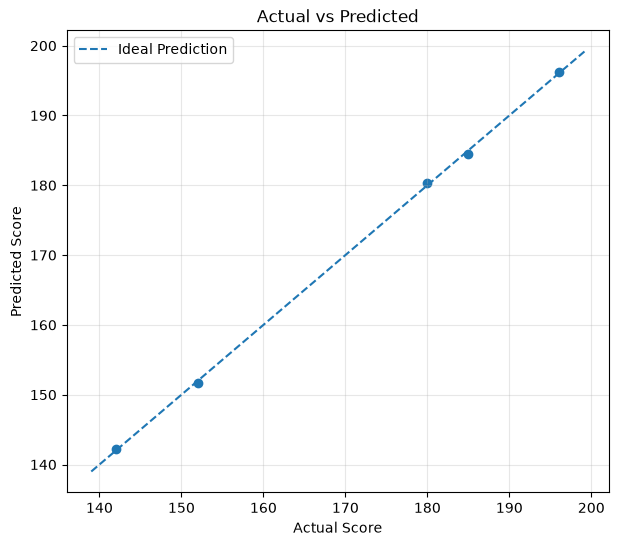

In [ ]:
#12_ 실제값과 예측값 시각화

actual_values = y_train.squeeze().numpy()
predicted_values = (predicted_score.squeeze().numpy())

score_min = min(actual_values.min(), predicted_values.min(),) - 3
score_max = max(actual_values.max(), predicted_values.max(),) + 3

plt.figure(figsize=(7, 6))
plt.scatter(actual_values, predicted_values,)

plt.plot([score_min, score_max], [score_min, score_max], 
    linestyle="--",label="Ideal Prediction",)

plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title("Actual vs Predicted")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 14. 핵심 정리

- 다중 선형회귀는 여러 입력 특성으로 하나의 값을 예측합니다.
- 각 특성은 자기 열의 평균과 표준편차로 표준화합니다.
- 실제 일반화 성능을 확인하려면 더 많은 데이터와 테스트 데이터가 필요합니다.